In [5]:
!pip uninstall -y qiskit-metal
!pip install -U quantum-metal

Found existing installation: qiskit-metal 0.1.5
Uninstalling qiskit-metal-0.1.5:
  Successfully uninstalled qiskit-metal-0.1.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 7.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 543.1/543.1 kB 19.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 83.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 10.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [quantum-metal]


In [6]:
import os

os.environ["QISKIT_METAL_HEADLESS"] = "True"

import qiskit_metal as qm
from qiskit_metal import designs, Dict

print("Qiskit Metal imported successfully!")
print("Version:", qm.__version__)

Qiskit Metal imported successfully!
Version: 0.9.0


In [7]:
from qiskit_metal.qlibrary.qubits.transmon_cross_fl import TransmonCrossFL
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.qlibrary.tlines.framed_path import RouteFramed
from qiskit_metal.qlibrary.tlines.anchored_path import RouteAnchors
from qiskit_metal.qlibrary.lumped.cap_n_interdigital import CapNInterdigital

design = designs.DesignPlanar()
design.chips.main.size.size_x = "6.0mm"
design.chips.main.size.size_y = "6.0mm"
design.overwrite_enabled = True

print("Design initialized with a 6x6 mm substrate.")

08:27PM 46s INFO [_start_renderers]: Renderer=hfss skipped: runtime dependency not installed (QAnsysRenderer requires pyEPR. Install with: pip install 'quantum-metal[ansys]').
08:27PM 46s INFO [_start_renderers]: Renderer=q3d skipped: runtime dependency not installed (QAnsysRenderer requires pyEPR. Install with: pip install 'quantum-metal[ansys]').
08:27PM 46s INFO [_start_renderers]: Renderer=gmsh skipped: runtime dependency not installed (renderer_gmsh requires gmsh. Install with: pip install 'quantum-metal[mesh]' (or the legacy alias 'quantum-metal[fem]')).
08:27PM 46s INFO [_start_renderers]: Renderer=aedt_q3d skipped: runtime dependency not installed (QPyaedt requires pyaedt (ansys.aedt.core). Install with: pip install 'quantum-metal[ansys]').
08:27PM 46s INFO [_start_renderers]: Renderer=aedt_hfss skipped: runtime dependency not installed (QPyaedt requires pyaedt (ansys.aedt.core). Install with: pip install 'quantum-metal[ansys]').


Design initialized with a 6x6 mm substrate.


In [8]:
qubit_pitch = 0.45  # mm
qubits, xy_pads = [], []
for i in range(5):
    x_pos = (i - 2) * qubit_pitch
    q = TransmonCrossFL(
        design,
        f"Q{i}",
        options=dict(
            pos_x=f"{x_pos}mm",
            pos_y="0.0mm",
            orientation="0",
            cross_width="30um",
            cross_length="190um",
            cross_gap="50um",
            make_fl=True,
            fl_options=dict(
                t_gap="3um",
                t_inductive_gap="3um",
                t_offset="0um",
                t_top="15um",
                t_width="5um",
            ),
            connection_pads=dict(
                readout=dict(
                    connector_type="0",
                    claw_length="40um",
                    ground_spacing="5um",
                    claw_width="10um",
                    claw_gap="6um",
                    connector_location="90",
                )
            ),
        ),
    )
    qubits.append(q)
    xy_pads.append(
        OpenToGround(
            design,
            f"XY_pad_{i}",
            options=dict(
                pos_x=f"{x_pos - 0.1}mm",
                pos_y="-0.18mm",
                orientation="90",
                width="10um",
                gap="6um",
                termination_gap="6um",
            ),
        )
    )

print("Placed qubits Q0-Q4 and their XY coupling pads.")

Placed qubits Q0-Q4 and their XY coupling pads.


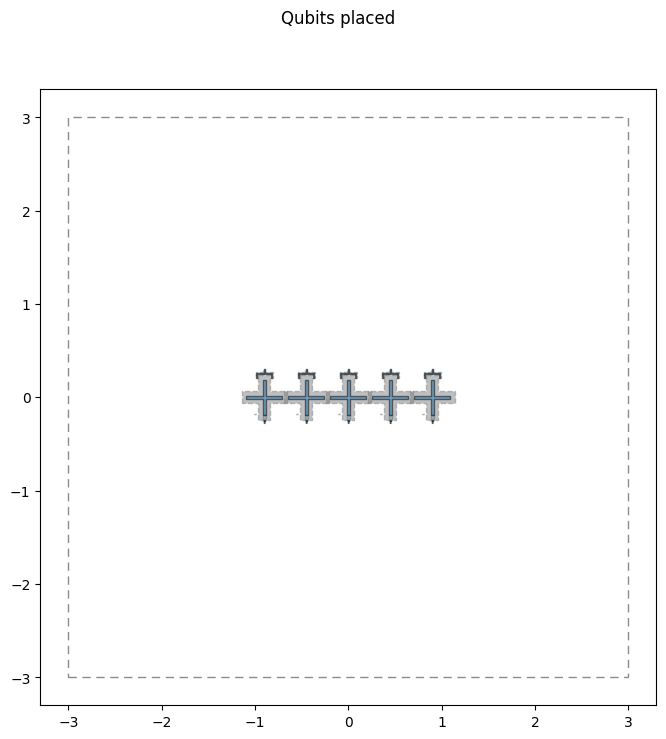

In [9]:
fig = qm.view(design)
fig.suptitle("Qubits placed")
fig

In [10]:
total_purcell_length_mm = 0  # tracked from the coupler taps onward

couplers = []
for i in range(5):
    x_pos = (i - 2) * qubit_pitch
    couplers.append(
        CoupledLineTee(
            design,
            f"CLT{i}",
            options=dict(
                pos_x=f"{x_pos}mm",
                pos_y="1.5mm",
                orientation="0",
                coupling_length="200um",
                coupling_space="4um",
                # Short the resonator end to ground: with the open claw at
                # the qubit, each readout resonator is a quarter-wave.
                open_termination=False,
            ),
        )
    )
    total_purcell_length_mm += 0.2

# Wirebond launchpads, three per edge, 1.5 mm apart
LaunchpadWirebond(
    design, "LP_W1", options=dict(pos_x="-2.8mm", pos_y="-1.5mm", orientation="0")
)
LaunchpadWirebond(
    design, "LP_W2", options=dict(pos_x="-2.8mm", pos_y="0.0mm", orientation="0")
)
LaunchpadWirebond(
    design, "LP_W3", options=dict(pos_x="-2.8mm", pos_y="1.5mm", orientation="0")
)
LaunchpadWirebond(
    design, "LP_E1", options=dict(pos_x="2.8mm", pos_y="-1.5mm", orientation="180")
)
LaunchpadWirebond(
    design, "LP_E2", options=dict(pos_x="2.8mm", pos_y="0.0mm", orientation="180")
)
LaunchpadWirebond(
    design, "LP_E3", options=dict(pos_x="2.8mm", pos_y="1.5mm", orientation="180")
)
LaunchpadWirebond(
    design, "LP_S1", options=dict(pos_x="-1.5mm", pos_y="-2.8mm", orientation="90")
)
LaunchpadWirebond(
    design, "LP_S2", options=dict(pos_x="0.0mm", pos_y="-2.8mm", orientation="90")
)
LaunchpadWirebond(
    design, "LP_S3", options=dict(pos_x="1.5mm", pos_y="-2.8mm", orientation="90")
)
LaunchpadWirebond(
    design, "LP_N1", options=dict(pos_x="-1.5mm", pos_y="2.8mm", orientation="270")
)
LaunchpadWirebond(
    design, "LP_N2", options=dict(pos_x="0.0mm", pos_y="2.8mm", orientation="270")
)
LaunchpadWirebond(
    design, "LP_N3", options=dict(pos_x="1.5mm", pos_y="2.8mm", orientation="270")
)

cap_in = CapNInterdigital(
    design, "Cap_input", options=dict(pos_x="-2.4mm", pos_y="1.5mm", orientation="270")
)
cap_out = CapNInterdigital(
    design, "Cap_output", options=dict(pos_x="-1mm", pos_y="2.1mm", orientation="90")
)

print("Placed launchpads and feedline terminations.")

  self.tables[kind] = pd.concat(



Placed launchpads and feedline terminations.


In [11]:
RouteStraight(
    design,
    "Feed_in_lp",
    options=dict(
        pin_inputs=dict(
            start_pin=dict(component="LP_W3", pin="tie"),
            end_pin=dict(component="Cap_input", pin="south_end"),
        )
    ),
)

purcell_left = RouteStraight(
    design,
    "Feed_in_clt",
    options=dict(
        pin_inputs=dict(
            start_pin=dict(component="Cap_input", pin="north_end"),
            end_pin=dict(component="CLT0", pin="prime_start"),
        )
    ),
)
total_purcell_length_mm += purcell_left.length

for i in range(4):
    feed_i = RouteStraight(
        design,
        f"Feed_mid_{i}",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"CLT{i}", pin="prime_end"),
                end_pin=dict(component=f"CLT{i + 1}", pin="prime_start"),
            )
        ),
    )
    total_purcell_length_mm += feed_i.length

purcell_right = RouteAnchors(
    design,
    "Feed_out_clt",
    options=dict(
        pin_inputs=dict(
            start_pin=dict(component="CLT4", pin="prime_end"),
            end_pin=dict(component="Cap_output", pin="north_end"),
        ),
        anchors=Dict({0: (1.7, 1.5), 1: (1.7, 1.8), 2: (-2.4, 1.8)}),
        fillet="100um",
        advanced=Dict(avoid_collision=False),
    ),
)
total_purcell_length_mm += purcell_right.length

RouteAnchors(
    design,
    "Feed_out_lp",
    options=dict(
        pin_inputs=dict(
            start_pin=dict(component="Cap_output", pin="south_end"),
            end_pin=dict(component="LP_N1", pin="tie"),
        ),
        lead=Dict(start_straight="200um", end_straight="100um"),
        fillet="20um",
        advanced=Dict(avoid_collision=False),
    ),
)

print("Feedline routed.")
print(f"Total Purcell-filter feedline length: {total_purcell_length_mm:.3f} mm")

Feedline routed.
Total Purcell-filter feedline length: 9.028 mm


In [12]:
resonator_lengths = ["4.41mm", "4.45mm", "4.49mm", "4.53mm", "4.57mm"]

for i in range(5):
    RouteMeander(
        design,
        f"ReadoutRes{i}",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"Q{i}", pin="readout"),
                end_pin=dict(component=f"CLT{i}", pin="second_end"),
            ),
            total_length=resonator_lengths[i],
            fillet="20um",
            lead=dict(start_straight="150um", end_straight="150um"),
            meander=dict(spacing="50um", asymmetry="0um"),
        ),
    )

print("Staggered meander resonators routed.")

08:28PM 13s WARNING [check_lengths]: For path table, component=ReadoutRes0, key=trace has short segments that could cause issues with fillet. Values in (29-30)  are index(es) in shapely geometry.
08:28PM 13s WARNING [check_lengths]: For path table, component=ReadoutRes0, key=cut has short segments that could cause issues with fillet. Values in (29-30)  are index(es) in shapely geometry.
08:28PM 13s WARNING [check_lengths]: For path table, component=ReadoutRes1, key=trace has short segments that could cause issues with fillet. Values in (29-30)  are index(es) in shapely geometry.
08:28PM 13s WARNING [check_lengths]: For path table, component=ReadoutRes1, key=cut has short segments that could cause issues with fillet. Values in (29-30)  are index(es) in shapely geometry.
08:28PM 13s WARNING [check_lengths]: For path table, component=ReadoutRes2, key=trace has short segments that could cause issues with fillet. Values in (29-30)  are index(es) in shapely geometry.
08:28PM 13s WARNING [che

Staggered meander resonators routed.


In [13]:
control_routes = [
    ("XY_pad_0", "open", "LP_W2", "tie", "XY_Line_0", Dict({})),
    ("Q0", "flux_line", "LP_W1", "tie", "Z_Line_0", Dict({})),
    (
        "XY_pad_1",
        "open",
        "LP_S1",
        "tie",
        "XY_Line_1",
        Dict({0: ["R", "50um"], 1: ["L", "2000um"], 2: ["R", "200um"]}),
    ),
    (
        "Q1",
        "flux_line",
        "LP_S2",
        "tie",
        "Z_Line_1",
        Dict({0: ["L", "100um"], 1: ["R", "2000um"], 2: ["L", "200um"]}),
    ),
    (
        "XY_pad_2",
        "open",
        "LP_S3",
        "tie",
        "XY_Line_2",
        Dict({0: ["R", "50um"], 1: ["L", "1800um"], 2: ["L", "500um"]}),
    ),
    (
        "Q2",
        "flux_line",
        "LP_E1",
        "tie",
        "Z_Line_2",
        Dict(
            {
                0: ["L", "100um"],
                1: ["R", "1600um"],
                2: ["L", "2500um"],
                3: ["L", "100um"],
            }
        ),
    ),
    (
        "XY_pad_3",
        "open",
        "LP_E2",
        "tie",
        "XY_Line_3",
        Dict(
            {
                0: ["R", "50um"],
                1: ["L", "1400um"],
                2: ["L", "2100um"],
                3: ["L", "1200um"],
            }
        ),
    ),
    (
        "Q3",
        "flux_line",
        "LP_E3",
        "tie",
        "Z_Line_3",
        Dict(
            {
                0: ["L", "100um"],
                1: ["R", "1200um"],
                2: ["L", "1700um"],
                3: ["L", "800um"],
            }
        ),
    ),
    (
        "XY_pad_4",
        "open",
        "LP_N3",
        "tie",
        "XY_Line_4",
        Dict(
            {
                0: ["R", "50um"],
                1: ["L", "1000um"],
                2: ["L", "1350um"],
                3: ["L", "3700um"],
                4: ["L", "400um"],
            }
        ),
    ),
    (
        "Q4",
        "flux_line",
        "LP_N2",
        "tie",
        "Z_Line_4",
        Dict(
            {
                0: ["L", "100um"],
                1: ["R", "800um"],
                2: ["L", "950um"],
                3: ["L", "3300um"],
                4: ["L", "400um"],
            }
        ),
    ),
]

for start_comp, start_pin, end_comp, end_pin, route_name, jogs in control_routes:
    route_options = dict(
        pin_inputs=dict(
            start_pin=dict(component=start_comp, pin=start_pin),
            end_pin=dict(component=end_comp, pin=end_pin),
        ),
        lead=dict(
            start_straight="100um", end_straight="50um", start_jogged_extension=jogs
        ),
        fillet="20um",
        step_size="0.05mm",
    )
    if "XY" in route_name:
        route_options["lead"]["start_straight"] = "200um"
    RouteFramed(design, route_name, options=route_options)

print("XY and Z control lines routed.")
print(f"Total components: {len(design.components)}")

XY and Z control lines routed.
Total components: 52


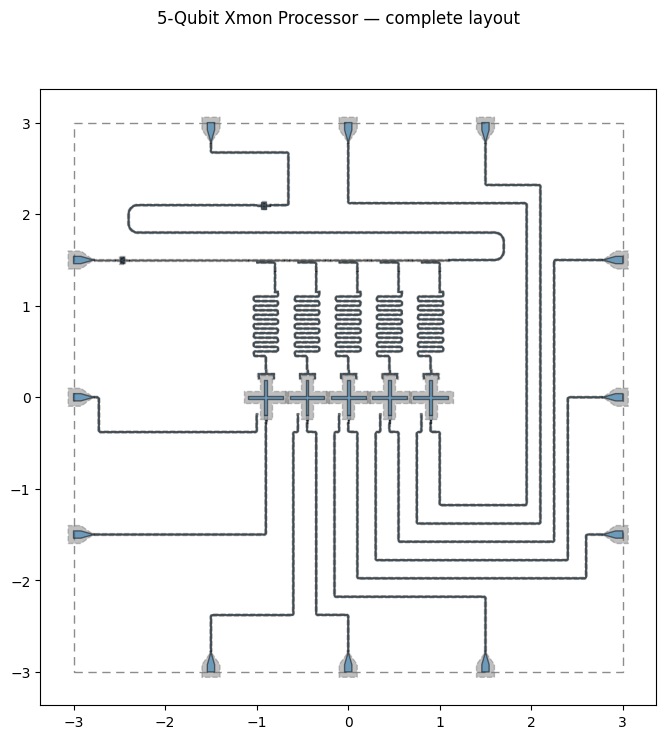

In [14]:
fig = qm.view(design)
fig.suptitle("5-Qubit Xmon Processor — complete layout")
fig

In [15]:
import logging
import tempfile
from pathlib import Path

out = Path(tempfile.gettempdir()) / "barends_5qubit_processor.gds"
gds_renderer = design.renderers.gds
gds_renderer.options.short_segments_to_not_fillet = "False"

# The renderer logs notes on cheesing, and that no junction GDS file is set
# (options.path_filename defaults to None, so the junctions are left out of
# the mask); show errors only while exporting.
level = qm.logger.level
qm.logger.setLevel(logging.ERROR)
try:
    gds_renderer.export_to_gds(str(out))
finally:
    qm.logger.setLevel(level)
print(f"Layout exported to GDSII: {out.name}")

  geopandas.GeoDataFrame(pd.concat(copy_subtract, ignore_index=False))

  geopandas.GeoDataFrame(pd.concat(copy_no_subtract, ignore_index=False))



Layout exported to GDSII: barends_5qubit_processor.gds


## Electromagnetic analysis: CPW transmission-line model

This section adds an **analytical/quasi-TEM electromagnetic model** alongside the Qiskit Metal geometry. It estimates the characteristic impedance, capacitance/inductance per unit length, phase velocity, wavelength, and quarter-wave resonance frequencies of the readout resonators.

**Important modelling assumptions:** the notebook does not explicitly set the feedline's CPW centre width and gap, so the values below are example parameters. Replace them with the actual dimensions used by your Qiskit Metal routes before treating the results as properties of your layout. The model assumes a thin CPW on a thick dielectric substrate, uses \(\epsilon_\mathrm{eff}\approx(\epsilon_r+1)/2\), and neglects conductor/dielectric loss, finite ground width, substrate thickness, bends, coupling, and full-wave effects. It is not a substitute for HFSS.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ellipk

# ---- CPW geometry: EXAMPLE values; replace with your actual feedline dimensions ----
w = 10e-6              # centre conductor width (m)
g = 6e-6               # gap between centre conductor and each ground (m)
eps_r = 11.45          # approximate relative permittivity of silicon
c0 = 299_792_458       # speed of light (m/s)

# ---- Quasi-TEM CPW approximation ----
k = w / (w + 2*g)
k_comp = np.sqrt(1 - k**2)

# scipy.special.ellipk() takes the parameter m = k^2, not modulus k
K_k = ellipk(k**2)
K_k_comp = ellipk(k_comp**2)

eps_eff = (eps_r + 1) / 2
Z0 = (30 * np.pi / np.sqrt(eps_eff)) * (K_k_comp / K_k)
vp = c0 / np.sqrt(eps_eff)

# Per-unit-length parameters for a lossless quasi-TEM line
L_per_m = Z0 / vp
C_per_m = 1 / (Z0 * vp)

print(f"CPW centre width       : {w*1e6:.2f} um")
print(f"CPW gap                : {g*1e6:.2f} um")
print(f"Effective permittivity : {eps_eff:.3f}")
print(f"Characteristic Z0      : {Z0:.2f} ohm")
print(f"Phase velocity         : {vp:.3e} m/s")
print(f"Inductance per length  : {L_per_m*1e9:.3f} nH/m")
print(f"Capacitance per length : {C_per_m*1e12:.3f} pF/m")

# ---- Estimate quarter-wave frequencies of the five readout resonators ----
# These are the lengths specified in the layout cell above.
resonator_lengths_m = np.array([4.41, 4.45, 4.49, 4.53, 4.57]) * 1e-3
resonator_names = [f"ReadoutRes{i}" for i in range(5)]
f_quarter_wave = vp / (4 * resonator_lengths_m)

print("\nIdeal quarter-wave resonance estimates (uncoupled, lossless):")
for name, length, freq in zip(resonator_names, resonator_lengths_m, f_quarter_wave):
    print(f"{name}: length = {length*1e3:.3f} mm, f ≈ {freq/1e9:.3f} GHz")

plt.figure(figsize=(8, 4))
plt.plot(np.arange(5), f_quarter_wave / 1e9, "o-", linewidth=2)
plt.xticks(np.arange(5), resonator_names)
plt.ylabel("Estimated resonance frequency (GHz)")
plt.title("Quarter-wave readout resonator estimates")
plt.grid(True)
plt.tight_layout()
plt.show()


## Transmission-line reflection: \(S_{11}\) versus frequency

The next cell calculates the input reflection coefficient of an ideal lossless transmission line terminated by a load. It demonstrates how a mismatch between the line impedance and load impedance produces reflections.

This is a **transmission-line circuit model**, not a full-wave EM simulation of the chip. The example line length and load below are illustrative; change them to match a physical test structure if you have those values.


In [ ]:
# Illustrative transmission-line reflection calculation
Z_source = Z0
Z_load = 45.0          # illustrative load impedance (ohm); change as required
line_length = 5e-3    # illustrative line length (m)

freq = np.linspace(1e9, 12e9, 2001)
beta = 2 * np.pi * freq / vp

# Input impedance of a lossless line terminated by Z_load
tan_bl = np.tan(beta * line_length)
Z_in = Z0 * (Z_load + 1j * Z0 * tan_bl) / (Z0 + 1j * Z_load * tan_bl)

# Voltage-wave reflection coefficient at the source reference plane
Gamma_in = (Z_in - Z_source) / (Z_in + Z_source)
S11_dB = 20 * np.log10(np.maximum(np.abs(Gamma_in), 1e-12))

plt.figure(figsize=(8, 4))
plt.plot(freq / 1e9, S11_dB)
plt.xlabel("Frequency (GHz)")
plt.ylabel(r"$|S_{11}|$ (dB)")
plt.title("Illustrative lossless transmission-line reflection")
plt.ylim(-80, 5)
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Line Z0 = {Z0:.2f} ohm, load = {Z_load:.2f} ohm, length = {line_length*1e3:.2f} mm")
print("A perfectly matched load (Z_load = Z0) gives zero reflection in this ideal model.")
